# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Derek Alcalá García  
**Grupo:** 511  **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
# 1.1 Importar bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)

# 1.2 Cargar el CSV (ruta relativa a la carpeta del notebook)
ruta = "../data/raw/nyc_taxi_examen.csv"
df = pd.read_csv(ruta)

# 1.3 Primeras cinco filas, dimensiones, columnas y tipos de datos
print("Primeras cinco filas:")
display(df.head())

print("Dimensiones (filas, columnas):", df.shape)

print("\nNombres de las columnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

Primeras cinco filas:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones (filas, columnas): (2427612, 20)

Nombres de las columnas:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:
VendorID                   int64
tpep_pickup_datetime      object
tpep_dropoff_datetime     object
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type             float64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport

In [2]:
# 1.4 Resumen estadístico de las columnas numéricas
display(df.describe().round(2))

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2427612.00,2415489.00,2415470.00,2415474.00,2415487.00,2415475.00,2415487.00,2415488.00,2415487.00,2415462.00,2415459.00,2415465.00,2415481.00,2415484.00,2415457.00,2415481.00,2415462.00,2415475.00
mean,1.89,1.30,3.30,4.23,164.14,163.22,1.17,38.53,1.57,0.48,3.67,0.59,0.99,29.38,2.25,0.20,0.56,15.61
std,0.81,1.88,5.17,17.20,62.85,69.26,0.46,542.38,1.91,0.10,4.23,2.39,0.16,25.93,0.78,0.63,0.33,260.58
min,1.00,-5.00,-99.99,1.00,1.00,1.00,1.00,-1849.60,-7.50,-0.50,-90.00,-106.46,-1.00,-1866.89,-2.50,-2.00,-0.75,-300517.52
25%,2.00,1.00,0.99,1.00,132.00,113.00,1.00,9.30,0.00,0.50,1.00,0.00,1.00,16.38,2.50,0.00,0.75,7.28
50%,2.00,1.00,1.70,1.00,161.00,162.00,1.00,13.50,1.00,0.50,2.95,0.00,1.00,21.54,2.50,0.00,0.75,12.32
75%,2.00,1.00,3.36,1.00,232.00,234.00,1.00,21.90,2.50,0.50,4.56,0.00,1.00,31.45,2.50,0.00,0.75,20.12
max,7.00,100.00,1686.49,99.00,265.00,265.00,4.00,19995.59,23.25,11.50,444.44,616.79,1.00,5530.74,2.75,27.00,0.75,8373.67


In [3]:
# 1.5 Valores existentes en payment_type
print("Valores únicos de payment_type:", df["payment_type"].unique())
print("\nConteo por valor (incluye nulos):")
print(df["payment_type"].value_counts(dropna=False))

Valores únicos de payment_type: [ 1.  2. nan  4.  3.]

Conteo por valor (incluye nulos):
payment_type
1.0    2051983
2.0     329533
4.0      23558
NaN      12125
3.0      10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [4]:
# 2.1 Copia de los datos originales
df_limpio = df.copy()
print("Dimensiones antes de limpiar:", df_limpio.shape)

# 2.2 Nulos por columna y duplicados ANTES de la limpieza
print("\nValores nulos por columna:")
print(df_limpio.isnull().sum())
print("\nRegistros duplicados:", df_limpio.duplicated().sum())

Dimensiones antes de limpiar: (2427612, 20)

Valores nulos por columna:


VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64



Registros duplicados: 11961


In [5]:
# 2.3 Eliminar duplicados y filas con valores nulos
df_limpio = df_limpio.drop_duplicates().copy()
print("Después de eliminar duplicados:", df_limpio.shape)

df_limpio = df_limpio.dropna().copy()
print("Después de eliminar nulos:", df_limpio.shape)

# 2.4 Conservar solo los registros que cumplen TODAS las condiciones
filas_antes = len(df_limpio)

mascara_valida = (
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
)

df_limpio = df_limpio.loc[mascara_valida].copy()
print("Registros eliminados por las condiciones:", filas_antes - len(df_limpio))

# 2.5 Registros que quedan después de limpiar
print("\nDimensiones antes de limpiar:", df.shape)
print("Dimensiones después de limpiar:", df_limpio.shape)
print("Registros restantes:", len(df_limpio))

# Verificación
print("\n¿Quedan nulos?:", df_limpio.isnull().sum().sum())
print("¿Quedan duplicados?:", df_limpio.duplicated().sum())

Después de eliminar duplicados: (2415651, 20)


Después de eliminar nulos: (2196158, 20)


Registros eliminados por las condiciones: 99558

Dimensiones antes de limpiar: (2427612, 20)
Dimensiones después de limpiar: (2096600, 20)
Registros restantes: 2096600

¿Quedan nulos?: 0


¿Quedan duplicados?: 0


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [6]:
# 3.1 Filtrar viajes pagados en efectivo (Cash)
df_cash = df_limpio[df_limpio["payment_type"] == 2].copy()

# 3.2 Seleccionar solo las dos variables para el agrupamiento
X = df_cash[["trip_distance", "trip_duration"]].copy()

# 3.3 Cantidad de viajes filtrados y estadísticas descriptivas de X
print("Viajes pagados en efectivo:", len(df_cash))
print("Dimensiones de X:", X.shape)
display(X.describe().round(2))

Viajes pagados en efectivo: 282085
Dimensiones de X: (282085, 2)


,trip_distance,trip_duration
count,282085.00,282085.00
mean,3.84,17.51
std,6.21,40.68
min,0.01,0.03
25%,0.92,7.40
50%,1.70,12.42
75%,4.37,20.88
max,1686.49,8373.67


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [7]:
# 4.1 Aplicar log1p a las dos variables
X_log = np.log1p(X)

# 4.2 Crear el StandardScaler y ajustar/transformar X_log
escalador = StandardScaler()

# 4.3 Guardar los datos estandarizados en X_escalado
X_escalado = pd.DataFrame(
    escalador.fit_transform(X_log),
    columns=["trip_distance", "trip_duration"],
    index=X.index
)

# 4.4 Resumen de las variables transformadas y estandarizadas
print("Variables después de log1p:")
display(X_log.describe().round(4))

print("Variables después de log1p + StandardScaler (media ≈ 0, desviación ≈ 1):")
display(X_escalado.describe().round(4))

Variables después de log1p:


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,1.2255,2.6076
std,0.7633,0.7445
min,0.0100,0.0328
25%,0.6523,2.1282
50%,0.9933,2.5965
75%,1.6808,3.0857
max,7.4310,9.0330


Variables después de log1p + StandardScaler (media ≈ 0, desviación ≈ 1):


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,-0.0000,-0.0000
std,1.0000,1.0000
min,-1.5924,-3.4587
25%,-0.7509,-0.6439
50%,-0.3042,-0.0149
75%,0.5966,0.6422
max,8.1299,8.6310


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

In [8]:
# 5.1 - 5.4 Evaluar k = 2 a 6 con inercia y silueta
valores_k = range(2, 7)
inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)

    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(X_escalado, etiquetas,
                                     sample_size=5000, random_state=42))

# 5.5 Tabla comparativa
resultados = pd.DataFrame({
    "k": list(valores_k),
    "Inercia": inercias,
    "Silueta": siluetas
})
display(resultados.round(4))

,k,Inercia,Silueta
0,2,227681.2292,0.5320
1,3,137511.9588,0.4478
2,4,100620.1949,0.4191
3,5,79205.3717,0.3894
4,6,66980.3104,0.3737


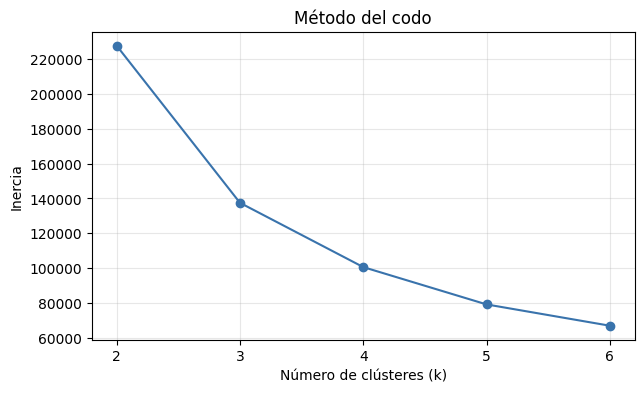

In [9]:
# 5.6 Gráfica 1: método del codo
plt.figure(figsize=(7, 4))
plt.plot(resultados["k"], resultados["Inercia"], marker="o", color="#3973ac")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)
plt.show()

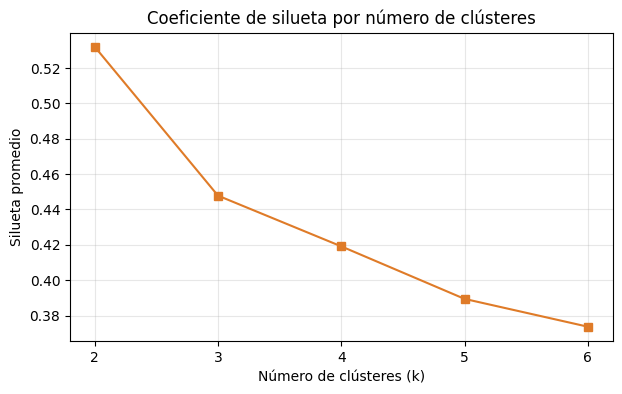

In [10]:
# 5.6 Gráfica 2: coeficiente de silueta
plt.figure(figsize=(7, 4))
plt.plot(resultados["k"], resultados["Silueta"], marker="s", color="#df7b28")
plt.title("Coeficiente de silueta por número de clústeres")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Silueta promedio")
plt.xticks(list(valores_k))
plt.grid(alpha=0.3)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

In [11]:
# 6.1 k elegido a partir del codo, la silueta y la claridad de los grupos
k_elegido = 3

# 6.2 Modelo final
modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)

# 6.3 Etiquetas de clúster para cada viaje
etiquetas_finales = modelo_final.fit_predict(X_escalado)

conteo = pd.Series(etiquetas_finales).value_counts().sort_index().to_frame("viajes")
conteo["porcentaje"] = (conteo["viajes"] / len(etiquetas_finales) * 100).round(1)
display(conteo)

,viajes,porcentaje
0,62395,22.1
1,125521,44.5
2,94169,33.4


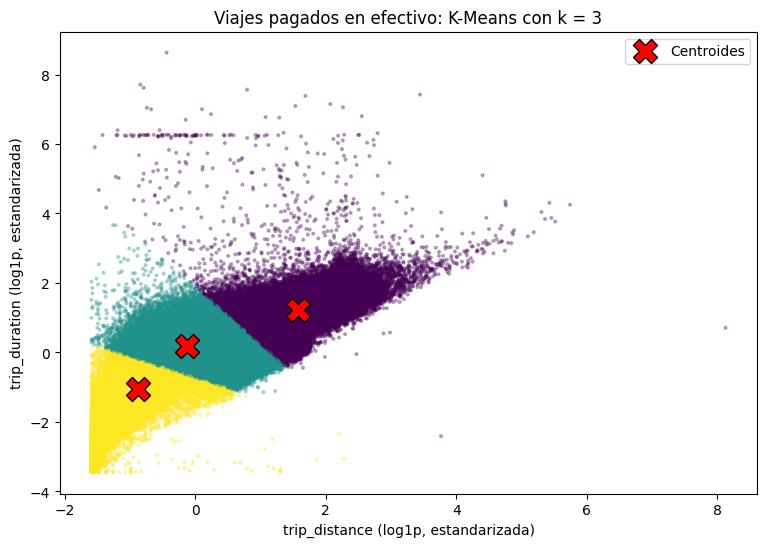

In [12]:
# 6.4 - 6.7 Dispersión en el espacio transformado y estandarizado con centroides
plt.figure(figsize=(9, 6))

plt.scatter(X_escalado["trip_distance"], X_escalado["trip_duration"],
            c=etiquetas_finales, cmap="viridis", s=4, alpha=0.3)

centroides = modelo_final.cluster_centers_
plt.scatter(centroides[:, 0], centroides[:, 1],
            marker="X", s=300, color="red", edgecolor="black",
            label="Centroides")

plt.title(f"Viajes pagados en efectivo: K-Means con k = {k_elegido}")
plt.xlabel("trip_distance (log1p, estandarizada)")
plt.ylabel("trip_duration (log1p, estandarizada)")
plt.legend()
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [13]:
# 7.1 DataFrame de resultados a partir de df_cash (unidades originales)
df_resultado = df_cash.copy()

# 7.2 Etiquetas del modelo final
df_resultado["cluster"] = etiquetas_finales

# 7.3 Estadísticos por clúster con los datos originales
estadisticos = df_resultado.groupby("cluster").agg(
    cantidad_viajes=("trip_distance", "size"),
    distancia_media_millas=("trip_distance", "mean"),
    distancia_mediana_millas=("trip_distance", "median"),
    duracion_media_min=("trip_duration", "mean"),
    duracion_mediana_min=("trip_duration", "median")
)

# 7.4 Tabla redondeada a dos decimales
display(estadisticos.round(2))

,cantidad_viajes,distancia_media_millas,distancia_mediana_millas,duracion_media_min,duracion_mediana_min
cluster,,,,,
0,62395,11.55,9.81,39.48,31.40
1,125521,2.30,1.94,15.43,14.00
2,94169,0.80,0.76,5.72,5.82


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:**
Elegí k = 3 porque la inercia disminuye bastante y después baja más lentamente. Aunque la silueta más alta es la de k = 2 (0.532), con k = 3 sigue siendo buena (0.448). Además, permite identificar tres grupos de viajes diferentes.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**
- **Clúster 2 — "Viajes muy cortos":** 94,169 viajes (33.4 %). Recorren en promedio 0.80 millas (mediana 0.76) y duran en promedio 5.72 minutos (mediana 5.82).
- **Clúster 1 — "Viajes típicos de ciudad":** 125,521 viajes (44.5 %). Recorren en promedio 2.30 millas (mediana 1.94) y duran en promedio 15.43 minutos (mediana 14.00).
- **Clúster 0 — "Viajes largos":** 62,395 viajes (22.1 %). Recorren en promedio 11.55 millas (mediana 9.81) y duran en promedio 39.48 minutos (mediana 31.40). Su media es bastante mayor que su mediana porque algunos viajes muy largos elevan el promedio.

**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:**
El clúster 0 (viajes largos) tiene la mayor duración promedio, con 39.48 minutos, y también la mayor distancia promedio, con 11.55 millas. Esto tiene lógica ya que los viajes más largos suelen durar más tiempo.

**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:**
El grupo más numeroso es el **clúster 1 (viajes típicos de ciudad)**, con 125,521 viajes (44.5 %). Sus viajes recorren en promedio 2.30 millas (mediana 1.94) y duran en promedio 15.43 minutos (mediana 14.00), por lo que son traslados normales dentro de la ciudad.

---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**